# Plotting with pandas, from one call to a finished chart

After this block you can draw a chart from a Series or a DataFrame with one call, choose a histogram, box plot, scatter plot, bar chart or line chart for a question, put several panels into one figure, and style a chart so that others can read it: title, labels, size, scale and colours.

## Overview

| Section | What it covers |
|---|---|
| The generic plot call | `data.plot.kind(options)` and what goes on each axis |
| Chart types | histograms, box plots, scatter plots, a map, bar charts, stacked bars, line charts |
| Many charts at once | subplots and layout, shared bins, `DataFrame.hist`, the scatter matrix |
| Styling a chart | arguments in the call, scales, colours, the Axes after the call, saving |
| Worked example · Where are the expensive listings? | one finished chart for a report |
| Check your understanding | four questions to vote on |
| Exercises | practice in pairs |
| Debrief | what to compare |
| Further reading | the pandas and matplotlib guides |

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

In [2]:
import pandas as pd                 # tables
import matplotlib.pyplot as plt     # pandas draws with matplotlib; plt is its usual short name

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")                # one row per listing
reviews_monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")  # one row per listing and month
listings.shape, reviews_monthly.shape

((10221, 42), (180656, 3))

## The generic plot call

### data.plot.kind(options)

Every pandas chart is one call with four parts:

| Part | What it is |
|---|---|
| `data` | a Series or a DataFrame |
| `.plot` | the plotting tools that every Series and DataFrame has |
| `.kind` | the kind of chart: `line`, `bar`, `barh`, `hist`, `box`, `scatter`, ... |
| `(options)` | which columns, the size, the colours, the title |

`data.plot(kind="line")` is another spelling of `data.plot.line()`; you will meet both. The call returns a matplotlib **Axes**, the box that holds the chart. Jupyter shows the chart below the cell; a script needs `plt.show()` at the end.

We start with a small made-up table, so every bar can be checked by eye.

In [3]:
# nights booked per month in two districts (made-up numbers); the months are the index
nights = pd.DataFrame({"Mitte": [120, 90, 140, 160], "Pankow": [60, 50, 80, 90]},
                      index=pd.Index(["Jan", "Feb", "Mar", "Apr"], name="month"))
nights

,Mitte,Pankow
month,,
Jan,120,60
Feb,90,50
Mar,140,80
Apr,160,90


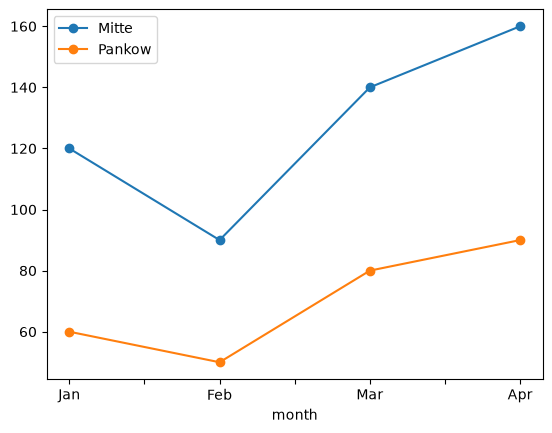

In [4]:
# data = nights, kind = line, option marker="o" draws a dot at every value
nights.plot.line(marker="o")
plt.show()

### What goes on the axes

pandas puts the **index on the x-axis** and the **values on the y-axis**. A Series gives one series of marks; a DataFrame gives one series per column, named in the legend after the column.

**Predict.** How many bars will `nights.plot.bar()` draw, and what will the legend say?

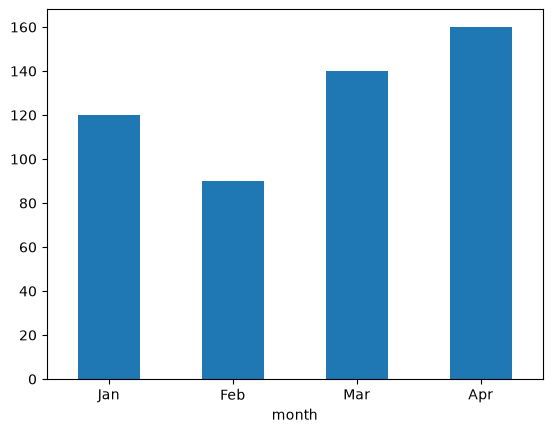

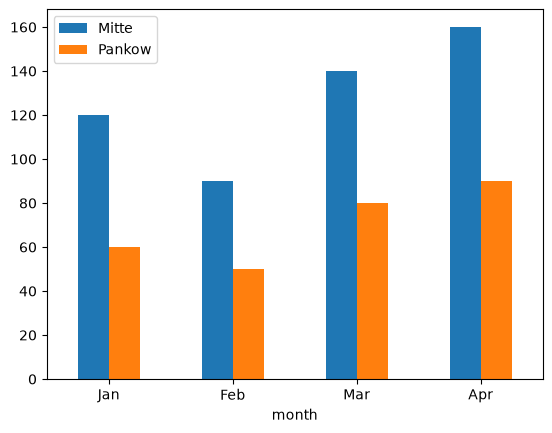

In [5]:
nights["Mitte"].plot.bar(rot=0)   # one column, a Series: 4 bars; rot=0 keeps the labels horizontal
plt.show()
nights.plot.bar(rot=0)            # two columns: 4 groups of 2 bars, and a legend
plt.show()

After `reset_index()` the months are a column and the index is 0, 1, 2, 3, so the x-axis shows numbers. `x=` names the column for the x-axis instead.

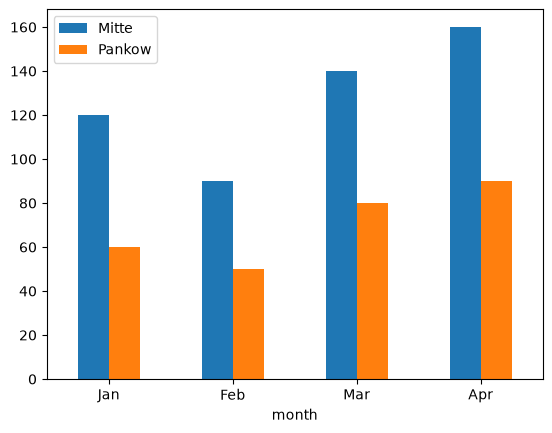

In [6]:
nights.reset_index().plot.bar(x="month", rot=0)   # x= puts the column month on the x-axis
plt.show()

## Chart types

Start from the question, not from the chart type:

| Question | Kind |
|---|---|
| How are the values of one column spread? | histogram, box plot |
| How does that spread differ between groups? | `hist(by=...)`, `boxplot(by=...)` |
| Do two numbers move together? | scatter plot |
| How many rows has each category? | bar chart, `barh` |
| How does a number change over time? | line chart |

### Histograms by group

A histogram cuts one number column into **bins** of equal width and counts the rows in each bin. `DataFrame.hist(column=..., by=...)` draws one panel per group. A few prices go up to 10,025 EUR and would squash the axis, so we keep the listings under 500 EUR.

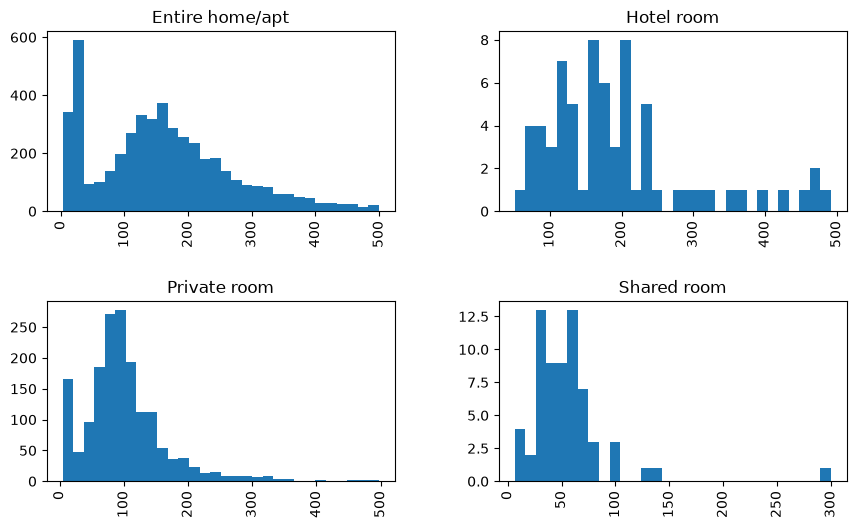

In [7]:
listings[listings["price"] < 500].hist(   # keep the listings under 500 EUR
    column="price",                       # the column to count
    by="room_type",                       # one panel per room type
    bins=30,                              # 30 bins of equal width in every panel
    figsize=(10, 6),                      # width and height of the figure in inches
)
plt.show()

What do you see? Look at the y-axes before comparing heights: each panel has its own y-axis, so compare the shapes, not the heights.

### Box plots by group

A box plot summarises a column in a few marks: the line is the **median**, the box holds the middle half of the rows (first to third quartile), the whiskers reach at most 1.5 box lengths further, and the dots beyond them are outliers. `boxplot(by=...)` puts one box per group on one shared y-axis.

**Predict.** For `pd.Series([40, 50, 55, 60, 65, 70, 300]).plot.box()`, at which value is the line inside the box?

median: 60.0  mean: 91.4


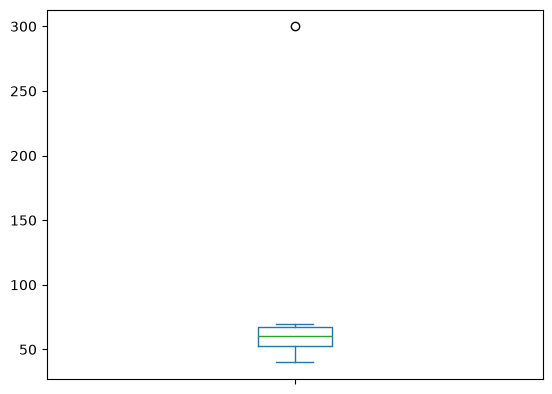

In [8]:
prices = pd.Series([40, 50, 55, 60, 65, 70, 300])
print("median:", prices.median(), " mean:", round(prices.mean(), 1))   # the box shows the median
prices.plot.box()
plt.show()

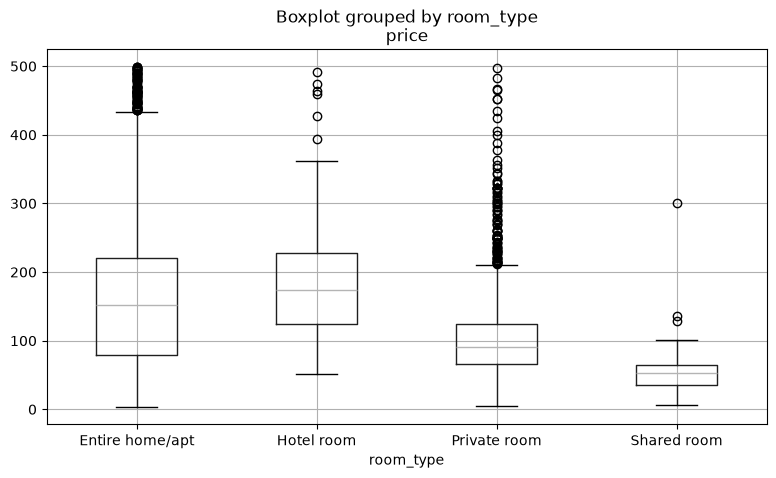

In [9]:
listings[listings["price"] < 500].boxplot(column="price", by="room_type", figsize=(9, 5))
plt.show()

### Scatter plots with colour

A scatter plot draws one dot per row at the position of two number columns. `c=` colours each dot by a third column, `colormap=` chooses the colours and `alpha=` makes the dots see-through, so dense areas show.

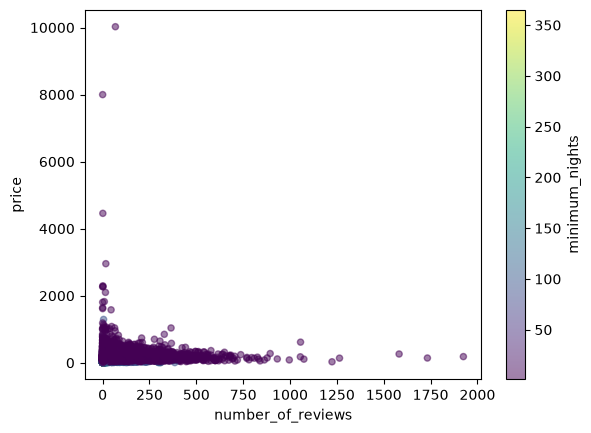

In [10]:
listings.plot.scatter(
    x="number_of_reviews", y="price",        # the two columns on the axes
    c="minimum_nights", colormap="viridis",  # colour each dot by the minimum stay
    alpha=0.5,                               # 0 = invisible, 1 = solid
)
plt.show()

What do you see? Almost every dot sits near price 0: a few listings up to 10,025 EUR stretch the y-axis. The section Log scale and limits fixes this.

### A map from longitude and latitude

With longitude on the x-axis and latitude on the y-axis, a scatter plot draws every listing where it is: a map, without any map library. John Snow drew the cholera deaths of 1854 in London the same way.

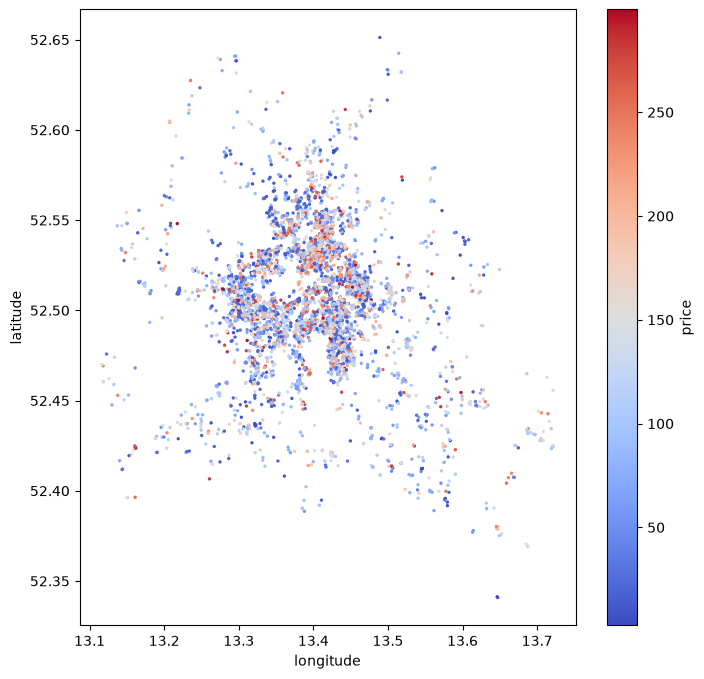

In [11]:
listings[listings["price"] < 300].plot.scatter(
    x="longitude", y="latitude",   # east-west and north-south
    c="price", cmap="coolwarm",    # cmap= is the same as colormap=: blue cheap, red expensive
    s=2,                           # dot size: small dots for thousands of points
    figsize=(8, 8),                # square, so the map is not stretched
)
plt.show()

### Bar charts of counts

`value_counts()` returns a Series with the categories as index and the counts as values, so `.plot.barh()` draws one horizontal bar per category. `barh` draws the first row at the bottom; `sort_values()` before it puts the longest bar on top.

district
Mitte                       2268
Friedrichshain-Kreuzberg    2119
Pankow                      1562
Charlottenburg-Wilm.        1146
Neukölln                    1046
Tempelhof - Schöneberg       675
Treptow - Köpenick           459
Lichtenberg                  318
Steglitz - Zehlendorf        285
Reinickendorf                141
Spandau                      107
Marzahn - Hellersdorf         95
Name: count, dtype: int64


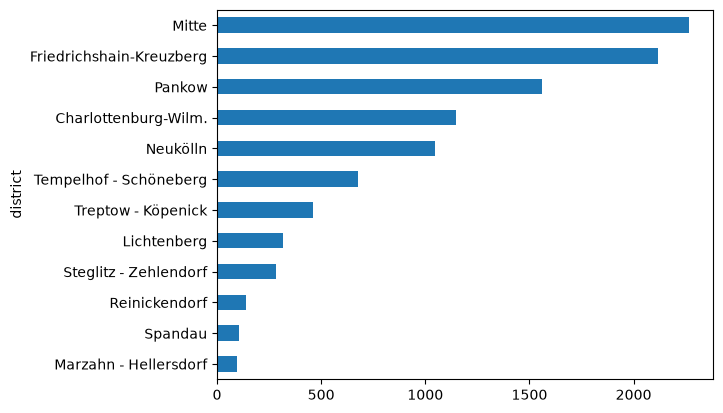

In [12]:
district_counts = listings["district"].value_counts()   # step 1: count the rows per district
print(district_counts)
district_counts.sort_values().plot.barh()                # step 2: draw them, longest on top
plt.show()

### Stacked bars from a cross table

Print a cross table before you plot it: one row per district, one column per room type, each cell a count.

In [13]:
rooms = pd.crosstab(listings["district"], listings["room_type"])   # counts of every pair
rooms

room_type,Entire home/apt,Hotel room,Private room,Shared room
district,,,,
Charlottenburg-Wilm.,770,14,362,0
Friedrichshain-Kreuzberg,1429,4,663,23
Lichtenberg,200,9,108,1
Marzahn - Hellersdorf,61,0,34,0
Mitte,1628,23,582,35
Neukölln,637,0,404,5
Pankow,1215,15,329,3
Reinickendorf,77,0,62,2
Spandau,67,3,37,0


`DataFrame.plot.bar()` draws one bar per row of the index and one colour per column. `stacked=True` piles the colours on top of each other, so each bar shows the district's total and its mix.

**Predict.** With `stacked=False`, how many bars would each district get?

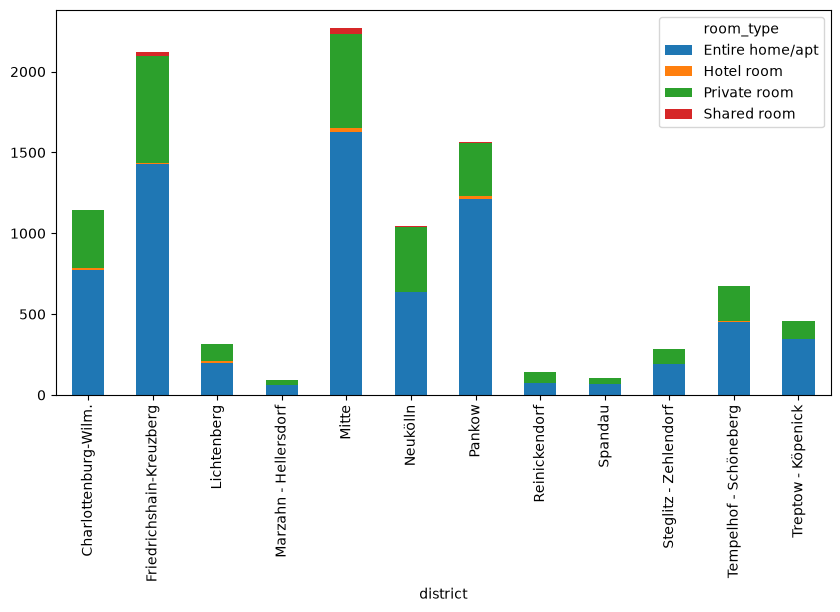

In [14]:
rooms.plot.bar(stacked=True, figsize=(10, 5))   # one bar per district, one coloured piece per room type
plt.show()

### Line charts with a rolling mean

`reviews_monthly` has one row per listing and month with at least one review. `groupby("month").size()` counts the rows per month: how many listings got a review in that month. `rolling(30).mean()` replaces every value with the mean of that row and the 29 before it.

**Predict.** One row is one month. Over how much time does `rolling(30)` average?

29 months without a value: the first 29 have fewer than 30 rows before them


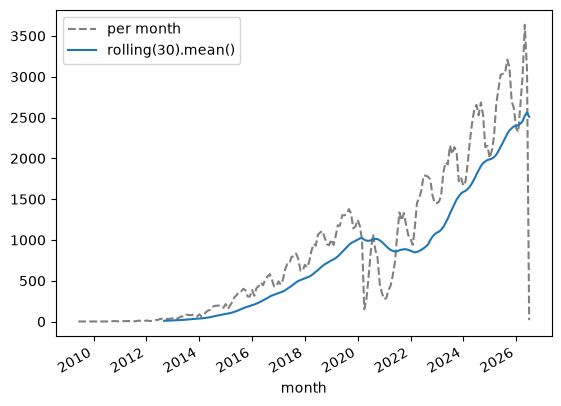

In [15]:
reviewed_per_month = reviews_monthly.groupby("month").size()   # one value per month
smoothed = reviewed_per_month.rolling(30).mean()               # mean of the last 30 rows = 30 months
print(smoothed.isna().sum(), "months without a value: the first 29 have fewer than 30 rows before them")

ax = reviewed_per_month.plot(color="grey", linestyle="--", label="per month")
smoothed.plot(ax=ax, label="rolling(30).mean()")   # ax=ax: draw into the same Axes
ax.legend()
plt.show()

`rolling(n)` counts **rows**, not days. Here one row is a month, so `rolling(30)` averages two and a half years. The last month in the data is not complete, so the grey line drops at the end.

## Many charts at once

### subplots and layout

`plot(subplots=True)` draws one panel per column instead of one chart for all. `layout=(rows, columns)` places the panels in a grid; rows × columns must be at least the number of columns. `figsize=` is the size of the whole figure, all panels together.

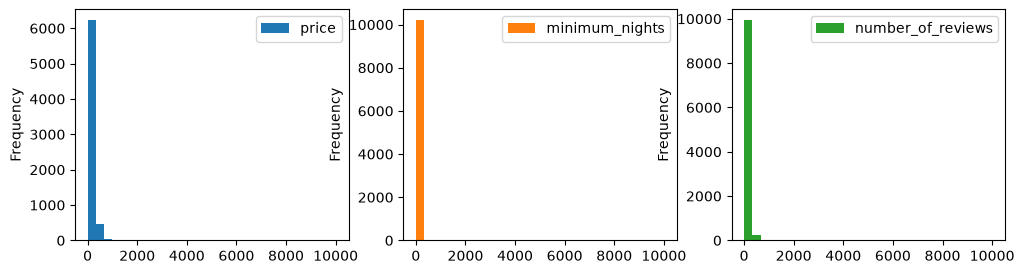

In [16]:
three = ["price", "minimum_nights", "number_of_reviews"]
listings[three].plot(
    kind="hist", subplots=True,   # one histogram per column
    layout=(1, 3),                # 1 row of 3 panels
    figsize=(12, 3), bins=30,
)
plt.show()

### Shared bins and DataFrame.hist

What do you see? The panels of `minimum_nights` and `number_of_reviews` are almost one single bar. **Predict.** Why?

`plot(kind="hist", subplots=True)` cuts all columns with **one set of bin edges**, computed over the values of all three columns together: 30 bins from 0 to 10,025, each about 334 wide. Almost every minimum stay is below 334 nights, so it falls into the first bin. `sharex=False` does not change the bins. `DataFrame.hist()` bins each column on its own:

price bin width: 334.1
minimum_nights bin width: 37.5
number_of_reviews bin width: 64.2


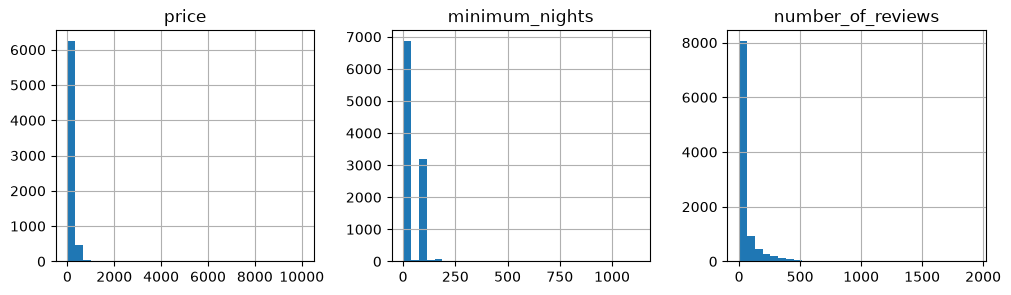

In [17]:
axes = listings[three].hist(bins=30, layout=(1, 3), figsize=(12, 3))   # own bins per column
for ax in axes.flat:                                                   # axes is an array of Axes
    print(ax.get_title(), "bin width:", round(ax.patches[0].get_width(), 1))
plt.show()

The long tails remain: a few very high values still push most rows into the first bars. A filter or a log scale (next section) shows the rest.

A layout that is too small stops with an error. The next cell fails on purpose:

In [18]:
try:
    listings[three + ["accommodates"]].plot(kind="hist", subplots=True, layout=(1, 3))
except ValueError as error:
    print("ValueError:", error)
plt.close("all")   # close the empty figure the failed call left behind

ValueError: Layout of 1x3 must be larger than required size 4


Read the message: `Layout of 1x3 must be larger than required size 4`. Four columns need at least four cells: use `layout=(2, 2)`.

### Scatter matrix

`pd.plotting.scatter_matrix` takes a DataFrame of n number columns and draws an n × n grid: every cell off the diagonal is a scatter plot of two columns, every cell on the diagonal the histogram of one column.

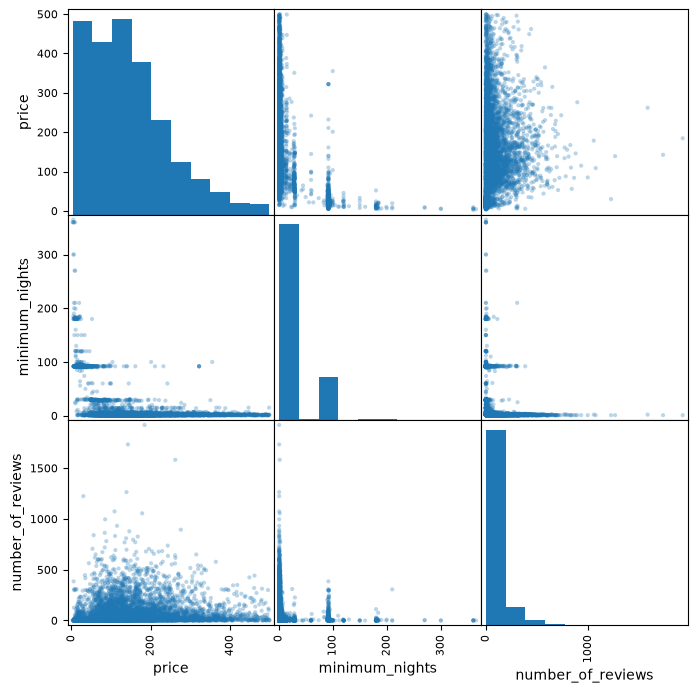

In [19]:
pd.plotting.scatter_matrix(
    listings.loc[listings["price"] < 500, three],   # filter the extreme prices first
    figsize=(8, 8), alpha=0.3,                      # 70 % see-through dots
)
plt.show()

## Styling a chart

### Arguments in the call

Most styling goes into the plot call as keyword arguments. A chart for other people needs at least a title and axis labels with units.

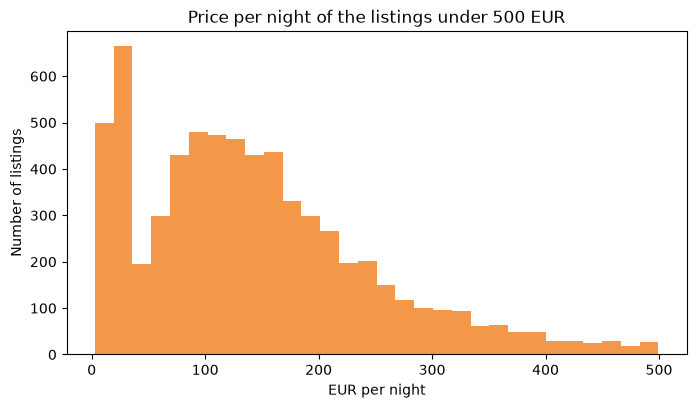

In [20]:
listings_under_500 = listings[listings["price"] < 500]   # the listings under 500 EUR

listings_under_500["price"].plot.hist(
    bins=30,
    figsize=(8, 4.2),                     # (width, height) in inches
    color="#f07f1a", alpha=0.8,           # one colour (a name or a hex code) and transparency
    title="Price per night of the listings under 500 EUR",
    xlabel="EUR per night", ylabel="Number of listings",
)
plt.show()

### Log scale and limits

When a few values are far larger than the rest, a linear axis squashes the rest near 0. `logy=True` spaces 10, 100 and 1,000 evenly; `ylim=(low, high)` cuts the axis instead and hides what lies outside.

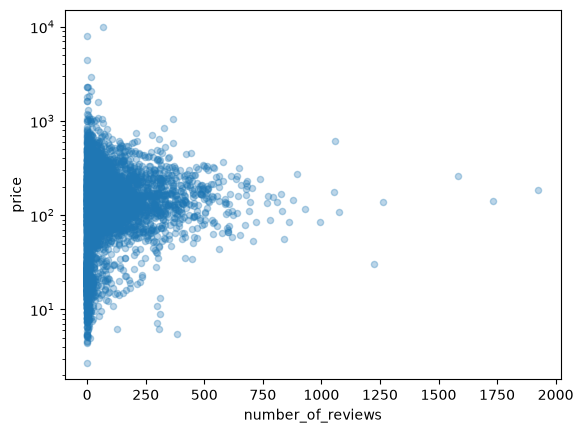

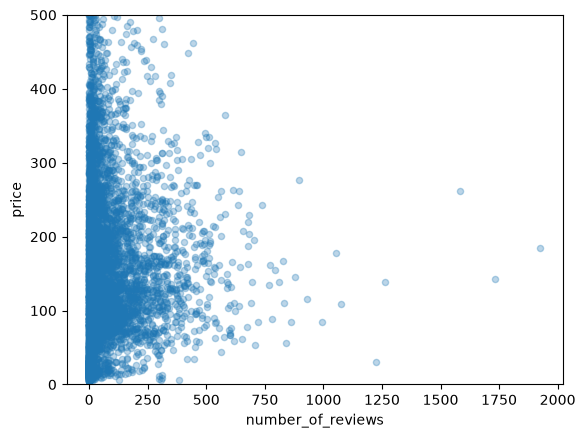

In [21]:
listings.plot.scatter(x="number_of_reviews", y="price", alpha=0.3, logy=True)   # log scale on y
plt.show()
listings.plot.scatter(x="number_of_reviews", y="price", alpha=0.3, ylim=(0, 500))  # cut at 500 EUR
plt.show()

### Colours and colormaps

- `color=` sets one colour for all marks: a name such as `"orange"` or a hex code such as `"#1f7a4d"`. A list gives one colour per column.
- `colormap=` (or `cmap=`) turns a column of numbers into colours. A **sequential** colormap such as `viridis` runs from low to high and stays readable in greyscale; a **diverging** one such as `coolwarm` shows values below and above a middle.

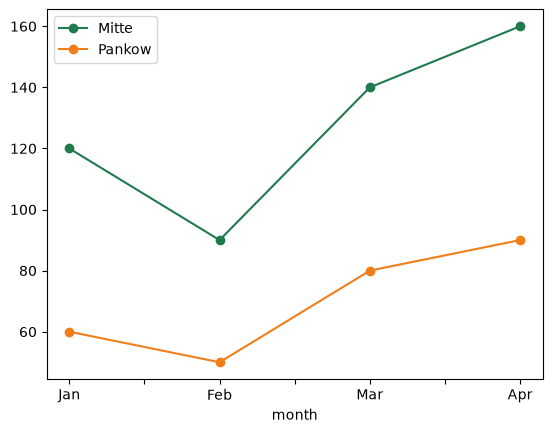

In [22]:
nights.plot.line(color=["#1f7a4d", "#f07f1a"], marker="o")   # one colour per column, in column order
plt.show()

### The Axes after the call

Every plot call returns a matplotlib Axes. Keep it in a variable to add what the call cannot, such as a reference line, and to change texts afterwards. `hist(by=...)` and `subplots=True` return an array of Axes, one per panel.

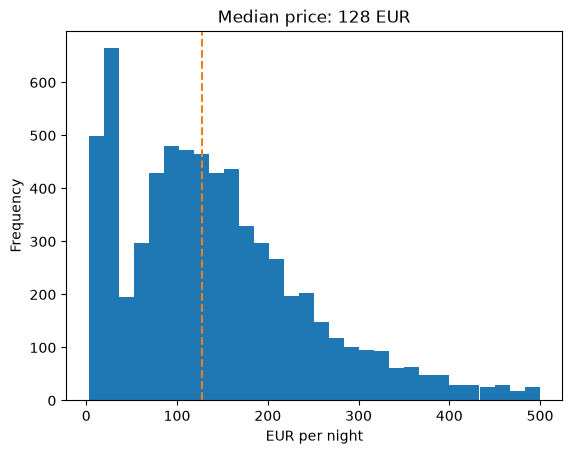

In [23]:
median_price = listings_under_500["price"].median()
ax = listings_under_500["price"].plot.hist(bins=30)               # keep the Axes
ax.axvline(median_price, color="#f07f1a", linestyle="--")         # a vertical line at the median
ax.set_title(f"Median price: {median_price:.0f} EUR")             # change the title afterwards
ax.set_xlabel("EUR per night")
plt.show()

### Saving a figure

`ax.figure.savefig(path)` saves the whole figure. `dpi=200` gives a sharp image, `bbox_inches="tight"` trims the white border. The notebook saves into a temporary folder, so nothing is written into the repository.

In [24]:
import tempfile

ax = listings_under_500["price"].plot.hist(bins=30, title="Prices under 500 EUR")
with tempfile.TemporaryDirectory() as folder:                  # a folder that is deleted afterwards
    path = Path(folder) / "prices.png"
    ax.figure.savefig(path, dpi=200, bbox_inches="tight")      # save the whole figure as PNG
    print("saved", path.name, path.stat().st_size // 1000, "kB")
plt.close(ax.figure)

saved prices.png 28 kB


## Worked example · Where are the expensive listings?

### Step 1 · Choose the chart

The question is about places and prices, so the chart is a map: a scatter plot of longitude and latitude, coloured by price.

### Step 2 · Choose the rows

**Why this step?** Very high prices would take the whole colour scale; keeping the listings under 300 EUR spreads the colours over the usual prices.

In [25]:
mapped_listings = listings[listings["price"] < 300]
len(mapped_listings)

6022

### Step 3 · Draw and label the map

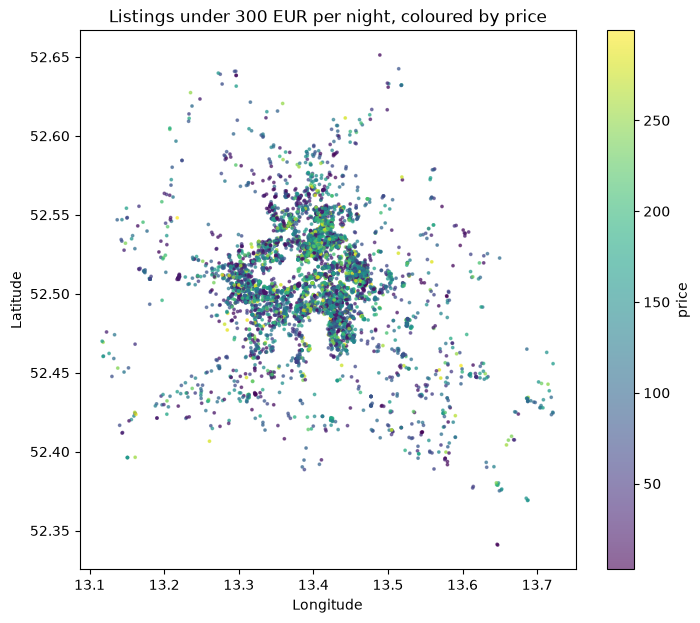

In [26]:
ax = mapped_listings.plot.scatter(
    x="longitude", y="latitude", c="price", cmap="viridis", s=3, alpha=0.6, figsize=(8, 7),
    title="Listings under 300 EUR per night, coloured by price",
    xlabel="Longitude", ylabel="Latitude",
)
plt.show()

### Step 4 · Check with a number

A map shows a pattern; a number checks it. Compare the median price per district with the colours on the map.

In [27]:
mapped_listings.groupby("district")["price"].median().sort_values(ascending=False).round(0)

district
Pankow                      134.0
Mitte                       132.0
Friedrichshain-Kreuzberg    127.0
Lichtenberg                 115.0
Neukölln                    110.0
Tempelhof - Schöneberg      104.0
Treptow - Köpenick          103.0
Charlottenburg-Wilm.        100.0
Steglitz - Zehlendorf        99.0
Spandau                      95.0
Marzahn - Hellersdorf        86.0
Reinickendorf                80.0
Name: price, dtype: float64

## Check your understanding

Vote alone first, then discuss with your neighbour, then vote again.

1. `nights.reset_index().plot.bar()`: what is on the x-axis? **A** Jan to Apr · **B** 0, 1, 2, 3 · **C** Mitte and Pankow · **D** an error
2. The line inside a box of a box plot shows: **A** the mean · **B** the median · **C** the first quartile · **D** the largest value
3. `reviews_monthly.groupby("month").size().rolling(30).mean()` averages over: **A** 30 days · **B** 30 months · **C** 30 listings · **D** 30 reviews
4. `figsize=(12, 3)` draws a figure that is: **A** 12 inches wide and 3 high · **B** 12 by 3 pixels · **C** 3 inches wide and 12 high · **D** 12 panels in 3 rows

## Exercises

Work in pairs; the lecturer picks which exercises to set.

### 5.1 · Entire homes under 300 EUR

*Code*

> Draw the prices of entire homes under 300 EUR as a histogram with 40 bins, a title and axis labels with units.

*Source: course exercise.*

### 5.2 · Mitte against Neukölln

*Code*

> Compare the prices of Mitte and Neukölln under 500 EUR as two box plots: filter the rows with `isin()`, then `boxplot(column="price", by="district")`.

*Source: course exercise.*

### 5.3 · Reviews since 2020

*Code*

> Plot the number of listings reviewed per month since 2020 with a 12-month rolling mean, label the axes and save the chart into a temporary folder as `reviews.png`.

*Source: course exercise.*

### 5.4 · Fix the chart

*Find the bug*

> The line below runs, but the chart is hard to read. Name three problems and fix them.
>
> ```python
> listings.plot.scatter(x="accommodates", y="price")
> ```

*Source: course exercise.*

### 5.5 · *Stretch:* Room types per district, as shares

*Pairs*

> Draw a stacked bar chart in which every district's bar has the same height, 1, and the pieces show the share of each room type. Hint: `pd.crosstab(..., normalize="index")`.

*Source: course exercise.*

## Debrief

- Compare two answers to 5.1: one with a title and units, one without. Which one could go into a report as it is?
- In 5.3, look for `rolling(12)` read as twelve days: one row is one month.
- In 5.4, the typical fixes are a filter or `logy=True`, `alpha=` for overlapping dots, and labels with units.

## Further reading

- pandas development team, [Chart visualization](https://pandas.pydata.org/docs/user_guide/visualization.html): every kind of chart and its options.
- Matplotlib development team, [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html): Figure, Axes and the two interfaces.
- Matplotlib development team, [Choosing colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html).
- Session 5 continues with choosing and designing charts, seaborn and Plotly.